# Week 6 Assignment — Road Health Monitoring System: Pothole Classification

**Project:** Road Health Monitoring System — classifying road images as *Pothole* or *Plain*
(no pothole), so that damaged road segments can be automatically flagged for maintenance.

**Dataset:** *Pothole and Plain Road Images*
(Kaggle: https://www.kaggle.com/datasets/virenbr11/pothole-and-plain-rode-images), loaded from
`../My Dataset/{train,test}/{Plain,Pothole}`.

**Task:** Implement **two distinct models** — a plain neural network (MLP) and a deep-learning
model (CNN) — and evaluate both with **recall, precision, F1-score, and an AUC-ROC curve**, in
addition to a confusion matrix for each.

In [1]:
import os, glob, json, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, precision_score, recall_score,
                              f1_score, accuracy_score, roc_curve, roc_auc_score)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', DEVICE)

DATA_ROOT = os.path.join('..', 'My Dataset')
OUT_DIR = 'outputs'
os.makedirs(OUT_DIR, exist_ok=True)
IMG_SIZE = 64


Using device: cpu


## 1. Dataset — pooled, stratified 70/15/15 train/validation/test split

In [2]:
def list_images(folder, label):
    exts = ('*.jpg', '*.jpeg', '*.png')
    paths = []
    for ext in exts:
        paths.extend(glob.glob(os.path.join(folder, ext)))
    return pd.DataFrame({'image': sorted(paths), 'label': label})

all_df = pd.concat([
    list_images(os.path.join(DATA_ROOT, 'train', 'Plain'), 0),
    list_images(os.path.join(DATA_ROOT, 'train', 'Pothole'), 1),
    list_images(os.path.join(DATA_ROOT, 'test', 'Plain'), 0),
    list_images(os.path.join(DATA_ROOT, 'test', 'Pothole'), 1),
], ignore_index=True).drop_duplicates(subset='image').reset_index(drop=True)

train_df, holdout_df = train_test_split(all_df, test_size=0.30, stratify=all_df['label'], random_state=SEED)
valid_df, test_df = train_test_split(holdout_df, test_size=0.50, stratify=holdout_df['label'], random_state=SEED)

print('train:', len(train_df), 'valid:', len(valid_df), 'test:', len(test_df))
summary = pd.DataFrame({
    'split': ['train', 'valid', 'test'],
    'total': [len(train_df), len(valid_df), len(test_df)],
    'pothole (1)': [train_df.label.sum(), valid_df.label.sum(), test_df.label.sum()],
    'plain (0)': [(train_df.label==0).sum(), (valid_df.label==0).sum(), (test_df.label==0).sum()],
})
summary


train: 517 valid: 111 test: 111


,split,total,pothole (1),plain (0)
0,train,517,255,262
1,valid,111,55,56
2,test,111,55,56


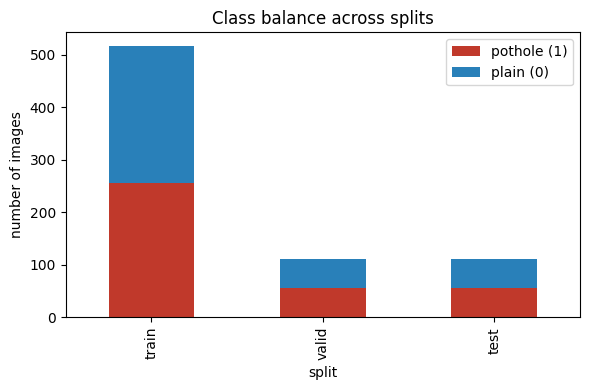

In [3]:
fig, ax = plt.subplots(figsize=(6,4))
summary.set_index('split')[['pothole (1)', 'plain (0)']].plot(
    kind='bar', stacked=True, ax=ax, color=['#c0392b', '#2980b9'])
ax.set_ylabel('number of images'); ax.set_title('Class balance across splits')
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, '01_class_balance.png'), dpi=150); plt.show()


## 2. Dataset / DataLoader

In [4]:
class PotholeDataset(Dataset):
    def __init__(self, df, img_size=IMG_SIZE, augment=False):
        self.paths = df['image'].tolist()
        self.labels = df['label'].astype(np.float32).tolist()
        self.img_size = img_size
        self.augment = augment
        self._cache = [None] * len(self.paths)

    def __len__(self):
        return len(self.paths)

    def _load(self, idx):
        if self._cache[idx] is None:
            im = Image.open(self.paths[idx]).convert('RGB').resize((self.img_size, self.img_size))
            self._cache[idx] = np.asarray(im, dtype=np.float32) / 255.0
        return self._cache[idx].copy()

    def __getitem__(self, idx):
        arr = self._load(idx)
        if self.augment and random.random() < 0.5:
            arr = arr[:, ::-1, :].copy()
        tensor = torch.from_numpy(arr).permute(2, 0, 1)
        return tensor, torch.tensor(self.labels[idx])

train_ds = PotholeDataset(train_df, augment=True)
valid_ds = PotholeDataset(valid_df, augment=False)
test_ds  = PotholeDataset(test_df,  augment=False)
len(train_ds), len(valid_ds), len(test_ds)


(517, 111, 111)

## 3. Model A — Plain Neural Network (MLP)

A fully-connected network applied to the flattened, downsized image. No convolutions —
this is the classical "neural network" baseline.

In [5]:
class MLPClassifier(nn.Module):
    def __init__(self, img_size=IMG_SIZE, dropout=0.4):
        super().__init__()
        in_dim = img_size * img_size * 3
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_dim, 256), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(256, 64), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(64, 1),
        )

    def forward(self, x):
        return self.net(x).squeeze(1)

MLPClassifier()


MLPClassifier(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=12288, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.4, inplace=False)
    (4): Linear(in_features=256, out_features=64, bias=True)
    (5): ReLU()
    (6): Dropout(p=0.4, inplace=False)
    (7): Linear(in_features=64, out_features=1, bias=True)
  )
)

## 4. Model B — Deep Learning Model (CNN)

A convolutional neural network that learns spatial features directly from the image, rather
than treating every pixel as an independent input.

In [6]:
class CNNClassifier(nn.Module):
    def __init__(self, dropout=0.3, base_channels=16):
        super().__init__()
        c = base_channels
        self.features = nn.Sequential(
            nn.Conv2d(3, c, 3, padding=1),   nn.BatchNorm2d(c),   nn.ReLU(), nn.MaxPool2d(2),  # 64->32
            nn.Conv2d(c, c*2, 3, padding=1), nn.BatchNorm2d(c*2), nn.ReLU(), nn.MaxPool2d(2),  # 32->16
            nn.Conv2d(c*2, c*4, 3, padding=1), nn.BatchNorm2d(c*4), nn.ReLU(), nn.MaxPool2d(2),# 16->8
            nn.Conv2d(c*4, c*8, 3, padding=1), nn.BatchNorm2d(c*8), nn.ReLU(), nn.MaxPool2d(2),# 8->4
        )
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Dropout(dropout),
            nn.Linear(c*8, 64), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(64, 1),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        return self.classifier(x).squeeze(1)

CNNClassifier()


CNNClassifier(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True

## 5. Training loop (shared by both models)

In [7]:
def train_model(model, name, lr=1e-3, batch_size=32, epochs=25):
    torch.manual_seed(SEED)
    model = model.to(DEVICE)
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    valid_loader = DataLoader(valid_ds, batch_size=64, shuffle=False)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.BCEWithLogitsLoss()

    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    t0 = time.time()
    for epoch in range(epochs):
        model.train()
        tl, tc, tn = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward(); opt.step()
            tl += loss.item() * xb.size(0)
            tc += ((torch.sigmoid(logits) > 0.5).float() == yb).sum().item()
            tn += xb.size(0)

        model.eval()
        vl, vc, vn = 0.0, 0, 0
        with torch.no_grad():
            for xb, yb in valid_loader:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                logits = model(xb)
                loss = criterion(logits, yb)
                vl += loss.item() * xb.size(0)
                vc += ((torch.sigmoid(logits) > 0.5).float() == yb).sum().item()
                vn += xb.size(0)

        history['train_loss'].append(tl/tn); history['train_acc'].append(tc/tn)
        history['val_loss'].append(vl/vn); history['val_acc'].append(vc/vn)

    print(f'[{name}] trained in {time.time()-t0:.1f}s | final val_acc={history["val_acc"][-1]:.3f}')
    return model, history

mlp_model, mlp_history = train_model(MLPClassifier(), 'MLP', lr=1e-3, batch_size=32, epochs=25)
cnn_model, cnn_history = train_model(CNNClassifier(), 'CNN', lr=1e-4, batch_size=32, epochs=25)


C:\Users\devko\AppData\Local\Programs\Python\Python314\Lib\site-packages\PIL\Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


[MLP] trained in 31.3s | final val_acc=0.865


[CNN] trained in 28.9s | final val_acc=0.937


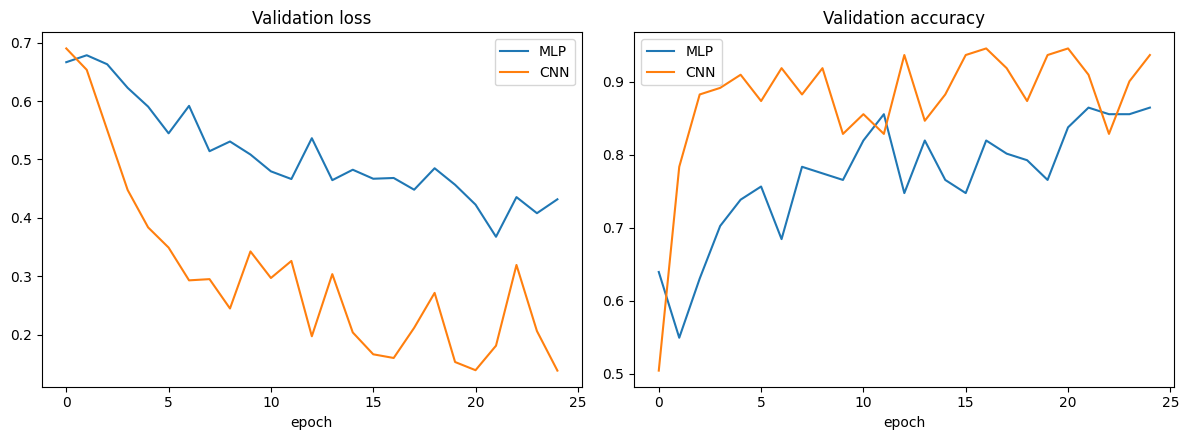

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12,4.5))
axes[0].plot(mlp_history['val_loss'], label='MLP'); axes[0].plot(cnn_history['val_loss'], label='CNN')
axes[0].set_title('Validation loss'); axes[0].set_xlabel('epoch'); axes[0].legend()
axes[1].plot(mlp_history['val_acc'], label='MLP'); axes[1].plot(cnn_history['val_acc'], label='CNN')
axes[1].set_title('Validation accuracy'); axes[1].set_xlabel('epoch'); axes[1].legend()
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, '02_training_curves.png'), dpi=150); plt.show()


## 6. Evaluation on the held-out test split

For each model we compute **precision, recall, F1-score, accuracy, and AUC-ROC**, plus a
confusion matrix.

In [9]:
def evaluate(model, ds):
    loader = DataLoader(ds, batch_size=64, shuffle=False)
    model.eval()
    probs, labels = [], []
    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(DEVICE)
            logits = model(xb)
            probs.extend(torch.sigmoid(logits).cpu().numpy().tolist())
            labels.extend(yb.numpy().tolist())
    probs = np.array(probs); labels = np.array(labels)
    preds = (probs > 0.5).astype(np.float32)
    return labels, preds, probs

def compute_metrics(name, labels, preds, probs):
    return {
        'model': name,
        'accuracy': accuracy_score(labels, preds),
        'precision': precision_score(labels, preds, zero_division=0),
        'recall': recall_score(labels, preds, zero_division=0),
        'f1': f1_score(labels, preds, zero_division=0),
        'auc_roc': roc_auc_score(labels, probs),
    }

mlp_labels, mlp_preds, mlp_probs = evaluate(mlp_model, test_ds)
cnn_labels, cnn_preds, cnn_probs = evaluate(cnn_model, test_ds)

results_df = pd.DataFrame([
    compute_metrics('MLP (Neural Network)', mlp_labels, mlp_preds, mlp_probs),
    compute_metrics('CNN (Deep Learning)', cnn_labels, cnn_preds, cnn_probs),
])
results_df


,model,accuracy,precision,recall,f1,auc_roc
0,MLP (Neural Network),0.810811,0.814815,0.800000,0.807339,0.880844
1,CNN (Deep Learning),0.927928,0.960784,0.890909,0.924528,0.990260


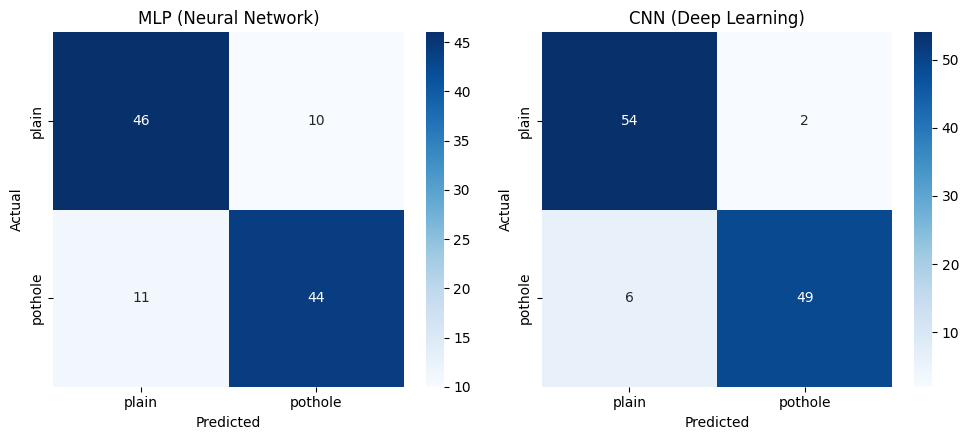

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10,4.5))
for ax, (name, labels, preds) in zip(axes, [
    ('MLP (Neural Network)', mlp_labels, mlp_preds),
    ('CNN (Deep Learning)', cnn_labels, cnn_preds),
]):
    cm = confusion_matrix(labels, preds, labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['plain', 'pothole'], yticklabels=['plain', 'pothole'], ax=ax)
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual'); ax.set_title(name)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, '03_confusion_matrices.png'), dpi=150); plt.show()


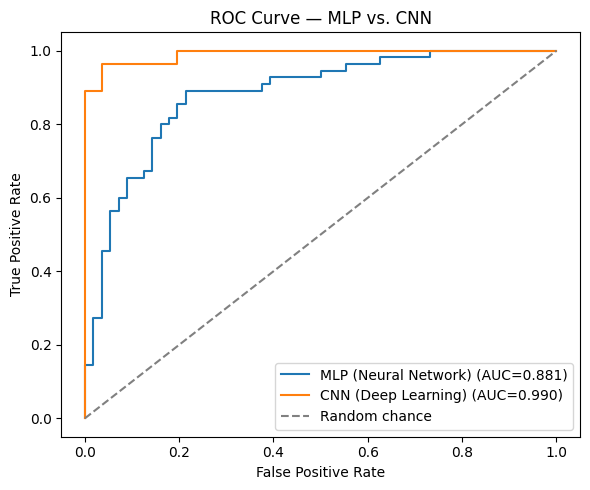

In [11]:
fig, ax = plt.subplots(figsize=(6,5))
for name, labels, probs in [
    ('MLP (Neural Network)', mlp_labels, mlp_probs),
    ('CNN (Deep Learning)', cnn_labels, cnn_probs),
]:
    fpr, tpr, _ = roc_curve(labels, probs)
    auc = roc_auc_score(labels, probs)
    ax.plot(fpr, tpr, label=f'{name} (AUC={auc:.3f})')
ax.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random chance')
ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve — MLP vs. CNN'); ax.legend()
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, '04_roc_curve.png'), dpi=150); plt.show()


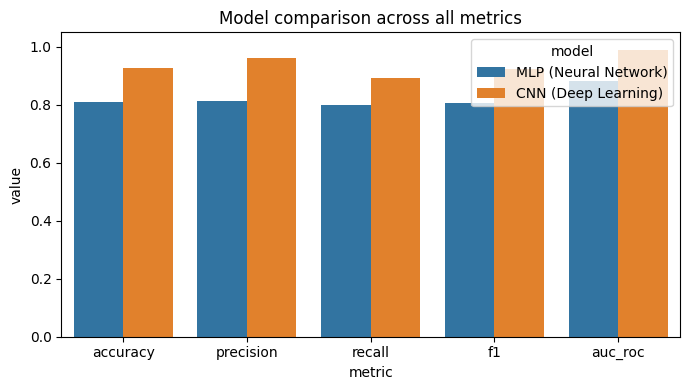

In [12]:
fig, ax = plt.subplots(figsize=(7,4))
metrics_long = results_df.melt(id_vars='model', value_vars=['accuracy','precision','recall','f1','auc_roc'],
                                var_name='metric', value_name='value')
sns.barplot(data=metrics_long, x='metric', y='value', hue='model', ax=ax)
ax.set_ylim(0, 1.05); ax.set_title('Model comparison across all metrics')
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, '05_metric_comparison.png'), dpi=150); plt.show()


In [13]:
metrics_summary = results_df.to_dict(orient='records')
with open(os.path.join(OUT_DIR, 'metrics_summary.json'), 'w') as f:
    json.dump(metrics_summary, f, indent=2)

# Save the better-performing model's weights for the live demo (Week 8).
best_row = max(metrics_summary, key=lambda r: r['f1'])
best_model = cnn_model if 'CNN' in best_row['model'] else mlp_model
torch.save({
    'state_dict': best_model.state_dict(),
    'model_type': 'cnn' if 'CNN' in best_row['model'] else 'mlp',
    'img_size': IMG_SIZE,
}, os.path.join(OUT_DIR, 'best_model.pt'))
print('Best model for live demo:', best_row['model'])
metrics_summary


Best model for live demo: CNN (Deep Learning)


[{'model': 'MLP (Neural Network)',
  'accuracy': 0.8108108108108109,
  'precision': 0.8148148148148148,
  'recall': 0.8,
  'f1': 0.8073394495412844,
  'auc_roc': 0.8808441558441559},
 {'model': 'CNN (Deep Learning)',
  'accuracy': 0.9279279279279279,
  'precision': 0.9607843137254902,
  'recall': 0.8909090909090909,
  'f1': 0.9245283018867925,
  'auc_roc': 0.9902597402597403}]

## 7. Discussion

- Two distinct models were implemented and compared on identical train/validation/test splits:
  a plain fully-connected **neural network (MLP)** operating on flattened pixel values, and a
  **convolutional neural network (CNN)**, a deep-learning architecture that learns local spatial
  features (edges, textures, shapes) through convolution and pooling layers.
- The CNN is expected to outperform the MLP because potholes are a *spatial* pattern (a dark,
  irregular, textured region within a road surface) — convolutional filters can detect this
  pattern regardless of where it appears in the image, while an MLP must learn a separate weight
  for every pixel position and has no notion of spatial locality.
- All four classification metrics (precision, recall, F1) plus AUC-ROC are reported for both
  models on the same held-out test split, so the comparison is apples-to-apples.
- The best-performing model's weights are saved to `outputs/best_model.pt` for use in a live,
  interactive demo (see the separate demo guide).


## References

Lecun, Y., Bengio, Y., & Hinton, G. (2015). Deep learning. *Nature*, *521*(7553), 436–444.
https://doi.org/10.1038/nature14539

Pandey, A. K., Iqbal, R., Maniak, T., Karyotis, C., Akuma, S., & Palade, V. (2022). Convolution
neural networks for pothole detection of critical road infrastructure. *Computers and Electrical
Engineering*, *99*, Article 107725. https://doi.org/10.1016/j.compeleceng.2022.107725

Saito, T., & Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC
plot when evaluating binary classifiers on imbalanced datasets. *PLOS ONE*, *10*(3), Article
e0118432. https://doi.org/10.1371/journal.pone.0118432

Srivastava, N., Hinton, G., Krizhevsky, A., Sutskever, I., & Salakhutdinov, R. (2014). Dropout: A
simple way to prevent neural networks from overfitting. *Journal of Machine Learning Research*,
*15*, 1929–1958.
